In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [5]:
from sklearn.model_selection import(
train_test_split,
cross_validate,
StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


### Dataset Loading and Initial Inspection

Objective

The purpose of this step is to load the heart failure dataset and inspect its basic structure before applying machine-learning algorithms.

Dataset Overview

- Total records: 12,000
- Total columns: 36
- File format: CSV (Comma-Separated Values)

Explanation

The dataset is loaded using the Pandas library. The "df.shape" command displays the number of rows and columns, while "df.head()" displays the first five records.

Interpretation

The dataset was loaded successfully and contains 12,000 records and 36 columns. Initial inspection helps us understand the available patient attributes before data cleaning and model training.

In [6]:
df = pd.read_csv("dataset_12000_records.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (12000, 36)


,Patient_ID,Age,Gender,BMI,Smoking_Status,Alcohol_Consumption,Exercise_Frequency,Hypertension,Diabetes,Chronic_Kidney_Disease,...,Blood_Glucose,BNP,Length_of_Stay,ICU_Admission,Emergency_Admission,Beta_Blocker,ACE_ARB,Diuretic,SGLT2_Inhibitor,Readmitted_30_Days
0,PT_00001,65,Female,25.564766,No,No,0,1,0,0,...,95.586026,118.407920,13,0,1,1,1,0,0,0
1,PT_00002,83,Male,30.503110,Yes,Yes,1,1,1,1,...,142.445450,421.440746,4,1,1,1,1,1,1,1
2,PT_00003,76,Male,21.934792,No,No,0,1,1,1,...,158.669171,240.351673,5,0,0,1,1,0,1,0
3,PT_00004,72,Female,22.048039,No,Yes,0,0,1,0,...,145.531173,334.414121,13,0,1,1,1,1,0,1
4,PT_00005,54,Male,27.102739,No,No,3,0,0,0,...,94.644198,71.006274,5,1,1,0,1,0,0,0


### Dataset Quality Assessment

Objective

The objective is to check the dataset's structure, missing values, duplicate records, data types, and target-class distribution before training the models.

Findings

- The dataset contains 12,000 rows and 36 columns.
- No missing values were found in the dataset.
- No duplicate rows were found.
- The target variable is "Readmitted_30_Days".
- Target value 0 represents patients who were not readmitted within 30 days, while value 1 represents patients who were readmitted within 30 days.
- The target distribution contains 8,400 class 0 records (70%) and 3,600 class 1 records (30%).

Interpretation

The dataset has no missing values or exact duplicate rows according to the checks performed. However, the target classes are imbalanced because non-readmitted cases represent 70% of the records and readmitted cases represent 30%. This distribution should be considered while evaluating model performance.

Further checks are required to identify suspicious values, confirm feature suitability, and assess potential data leakage.

In [7]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["Readmitted_30_Days"].value_counts())

print("\nTarget percentages:")
print(
    df["Readmitted_30_Days"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Number of rows and columns: (12000, 36)

Column names:
['Patient_ID', 'Age', 'Gender', 'BMI', 'Smoking_Status', 'Alcohol_Consumption', 'Exercise_Frequency', 'Hypertension', 'Diabetes', 'Chronic_Kidney_Disease', 'Coronary_Artery_Disease', 'Previous_Stroke', 'Atrial_Fibrillation', 'Previous_HF_Admissions', 'Previous_Hospital_Admissions', 'Heart_Failure_Type', 'NYHA_Class', 'Ejection_Fraction', 'Systolic_BP', 'Diastolic_BP', 'Heart_Rate', 'Oxygen_Saturation', 'Creatinine', 'Sodium', 'Potassium', 'Hemoglobin', 'Blood_Glucose', 'BNP', 'Length_of_Stay', 'ICU_Admission', 'Emergency_Admission', 'Beta_Blocker', 'ACE_ARB', 'Diuretic', 'SGLT2_Inhibitor', 'Readmitted_30_Days']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 36 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Patient_ID                    12000 non-null  object 
 1   Ag

In [8]:
print("Dataset shape:", df.shape)
print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (12000, 36)

Missing values per column:


,Missing Values
Patient_ID,0
Age,0
Gender,0
BMI,0
Smoking_Status,0
Alcohol_Consumption,0
Exercise_Frequency,0
Hypertension,0
Diabetes,0
Chronic_Kidney_Disease,0



Duplicate rows: 0


In [9]:
print("COLUMN DATA TYPES:")
display(df.dtypes.to_frame("Data Type"))

print("\nUNIQUE VALUES IN EACH COLUMN:")
display(df.nunique().to_frame("Unique Values"))

print("\nTARGET DISTRIBUTION:")
display(df["Readmitted_30_Days"].value_counts(dropna=False).sort_index())


COLUMN DATA TYPES:


,Data Type
Patient_ID,object
Age,int64
Gender,object
BMI,float64
Smoking_Status,object
Alcohol_Consumption,object
Exercise_Frequency,int64
Hypertension,int64
Diabetes,int64
Chronic_Kidney_Disease,int64



UNIQUE VALUES IN EACH COLUMN:


,Unique Values
Patient_ID,12000
Age,66
Gender,2
BMI,11883
Smoking_Status,2
Alcohol_Consumption,2
Exercise_Frequency,5
Hypertension,2
Diabetes,2
Chronic_Kidney_Disease,2



TARGET DISTRIBUTION:


Readmitted_30_Days
0    8400
1    3600
Name: count, dtype: int64

In [10]:
cat_cols = [
    "Gender",
    "Smoking_Status",
    "Alcohol_Consumption",
    "Heart_Failure_Type"
]

for col in cat_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


Gender:
Gender
Male      6941
Female    5059
Name: count, dtype: int64

Smoking_Status:
Smoking_Status
No     8971
Yes    3029
Name: count, dtype: int64

Alcohol_Consumption:
Alcohol_Consumption
No     9610
Yes    2390
Name: count, dtype: int64

Heart_Failure_Type:
Heart_Failure_Type
HFrEF     6679
HFmrEF    4044
HFpEF     1277
Name: count, dtype: int64


### Numeric Range and Binary Value Checks

Objective: To inspect numeric ranges and verify that binary variables contain only the expected values.

Findings:

- The numeric columns were inspected to identify their minimum and maximum values.
- The checked binary variables contain only 0 and 1.
- "Previous_HF_Admissions" and "Previous_Hospital_Admissions" are count variables, not binary variables.
- Some numeric values, such as BNP and creatinine, are relatively high and require contextual review.

Interpretation:
The binary-value checks did not reveal unexpected values in the listed columns. However, minimum and maximum values alone cannot establish whether every clinical measurement is valid. Further domain-based checks are needed before declaring the dataset free of impossible or suspicious values.

In [11]:
# Check whether numeric columns contain values outside their observed ranges
print("Minimum values:")
display(df.select_dtypes(include="number").min())

print("\nMaximum values:")
display(df.select_dtypes(include="number").max())

# Check the expected range of binary columns
binary_columns = [
    "Hypertension",
    "Diabetes",
    "Chronic_Kidney_Disease",
    "Coronary_Artery_Disease",
    "Previous_Stroke",
    "Atrial_Fibrillation",
    "ICU_Admission",
    "Emergency_Admission",
    "Beta_Blocker",
    "ACE_ARB",
    "Diuretic",
    "SGLT2_Inhibitor",
    "Readmitted_30_Days"
]

for col in binary_columns:
    print(col, sorted(df[col].dropna().unique()))

Minimum values:


Age                              30.000000
BMI                              16.000000
Exercise_Frequency                0.000000
Hypertension                      0.000000
Diabetes                          0.000000
Chronic_Kidney_Disease            0.000000
Coronary_Artery_Disease           0.000000
Previous_Stroke                   0.000000
Atrial_Fibrillation               0.000000
Previous_HF_Admissions            0.000000
Previous_Hospital_Admissions      0.000000
NYHA_Class                        1.000000
Ejection_Fraction                10.000000
Systolic_BP                      85.000000
Diastolic_BP                     50.000000
Heart_Rate                       50.000000
Oxygen_Saturation                84.502044
Creatinine                        0.500000
Sodium                          124.373997
Potassium                         2.800000
Hemoglobin                        7.000000
Blood_Glucose                    70.000000
BNP                              50.000000
Length_of_S


Maximum values:


Age                               95.000000
BMI                               45.975566
Exercise_Frequency                 4.000000
Hypertension                       1.000000
Diabetes                           1.000000
Chronic_Kidney_Disease             1.000000
Coronary_Artery_Disease            1.000000
Previous_Stroke                    1.000000
Atrial_Fibrillation                1.000000
Previous_HF_Admissions             7.000000
Previous_Hospital_Admissions       9.000000
NYHA_Class                         4.000000
Ejection_Fraction                 71.874767
Systolic_BP                      194.855837
Diastolic_BP                     120.000000
Heart_Rate                       132.041953
Oxygen_Saturation                100.000000
Creatinine                         8.000000
Sodium                           150.000000
Potassium                          6.418538
Hemoglobin                        18.000000
Blood_Glucose                    258.524090
BNP                             

Hypertension [np.int64(0), np.int64(1)]
Diabetes [np.int64(0), np.int64(1)]
Chronic_Kidney_Disease [np.int64(0), np.int64(1)]
Coronary_Artery_Disease [np.int64(0), np.int64(1)]
Previous_Stroke [np.int64(0), np.int64(1)]
Atrial_Fibrillation [np.int64(0), np.int64(1)]
ICU_Admission [np.int64(0), np.int64(1)]
Emergency_Admission [np.int64(0), np.int64(1)]
Beta_Blocker [np.int64(0), np.int64(1)]
ACE_ARB [np.int64(0), np.int64(1)]
Diuretic [np.int64(0), np.int64(1)]
SGLT2_Inhibitor [np.int64(0), np.int64(1)]
Readmitted_30_Days [np.int64(0), np.int64(1)]


### Additional Clinical Range Checks

These descriptive statistics help inspect whether selected clinical and admission-related columns contain suspicious values. They do not prove that every value is medically valid; any unusual values should be checked against the dataset documentation.


In [12]:
check_cols = [
    "Age", "BMI", "Exercise_Frequency",
    "NYHA_Class", "Ejection_Fraction",
    "Systolic_BP", "Diastolic_BP",
    "Heart_Rate", "Oxygen_Saturation",
    "Creatinine", "Sodium", "Potassium",
    "Hemoglobin", "Blood_Glucose", "BNP",
    "Length_of_Stay"
]

display(df[check_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Age,12000.0,67.40,13.08,30.00,60.00,68.00,77.00,95.00
BMI,12000.0,27.79,5.04,16.00,24.30,27.78,31.25,45.98
Exercise_Frequency,12000.0,1.02,1.04,0.00,0.00,1.00,2.00,4.00
NYHA_Class,12000.0,2.27,1.02,1.00,1.00,2.00,3.00,4.00
Ejection_Fraction,12000.0,38.64,9.19,10.00,32.68,38.70,44.73,71.87
Systolic_BP,12000.0,124.71,18.58,85.00,111.79,124.57,137.29,194.86
Diastolic_BP,12000.0,77.98,12.04,50.00,69.76,77.96,86.25,120.00
Heart_Rate,12000.0,83.82,12.37,50.00,75.28,83.79,92.24,132.04
Oxygen_Saturation,12000.0,94.26,2.59,84.50,92.48,94.27,96.06,100.00
Creatinine,12000.0,1.88,1.85,0.50,0.50,1.15,2.41,8.00


### Target Class Distribution

**Objective:** Check how many patients were and were not readmitted within 30 days.

The chart displays counts and percentages for both target classes. This helps identify whether the dataset is imbalanced, which can affect model evaluation. The target encoding is `0 = not readmitted` and `1 = readmitted`.


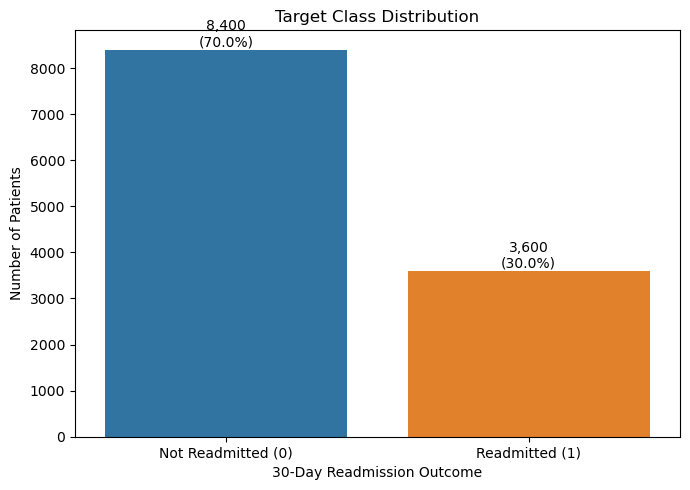

,Count,Percentage
Readmitted_30_Days,,
Not Readmitted,8400,70.0
Readmitted,3600,30.0


In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

target_counts = df["Readmitted_30_Days"].value_counts().reindex([0, 1], fill_value=0)
target_percentages = (target_counts / target_counts.sum() * 100).round(1)

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=["Not Readmitted (0)", "Readmitted (1)"],
    y=target_counts.values,
    hue=["Not Readmitted (0)", "Readmitted (1)"],
    legend=False
)

for bar, count, pct in zip(ax.patches, target_counts.values, target_percentages.values):
    ax.annotate(
        f"{count:,}\n({pct}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center", va="bottom"
    )

plt.title("Target Class Distribution")
plt.xlabel("30-Day Readmission Outcome")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
}).rename(index={0: "Not Readmitted", 1: "Readmitted"}))


### Additional Data Leakage Checks

These checks inspect features that may need special attention depending on when the prediction is made.

- `Length_of_Stay` and `ICU_Admission` should only be included if they are known at the intended prediction time.
- `Emergency_Admission`, `Previous_HF_Admissions`, and `Previous_Hospital_Admissions` may be useful when their values are available at prediction time.
- `Readmitted_30_Days` is the outcome being predicted and must not be included in the input features.

The project should define whether prediction occurs at admission, during the stay, or at discharge before deciding which features are appropriate.


In [14]:
print("CHECKING IMPORTANT COLUMNS")

for col in [
    "Length_of_Stay",
    "ICU_Admission",
    "Emergency_Admission",
    "Previous_HF_Admissions",
    "Previous_Hospital_Admissions",
    "Readmitted_30_Days"
]:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index().head(15))

CHECKING IMPORTANT COLUMNS

Length_of_Stay:
Length_of_Stay
1     1116
2      984
3     1051
4     1031
5      975
6      890
7      823
8      723
9      594
10     548
11     457
12     394
13     372
14     296
15     248
Name: count, dtype: int64

ICU_Admission:
ICU_Admission
0    7921
1    4079
Name: count, dtype: int64

Emergency_Admission:
Emergency_Admission
0    5860
1    6140
Name: count, dtype: int64

Previous_HF_Admissions:
Previous_HF_Admissions
0    6785
1    3503
2    1221
3     368
4      93
5      29
7       1
Name: count, dtype: int64

Previous_Hospital_Admissions:
Previous_Hospital_Admissions
0    2421
1    3643
2    2980
3    1725
4     788
5     305
6     111
7      13
8       9
9       5
Name: count, dtype: int64

Readmitted_30_Days:
Readmitted_30_Days
0    8400
1    3600
Name: count, dtype: int64


### Data Leakage Assessment

Objective

The objective is to identify features that could reveal information unavailable at the time of prediction and lead to overly optimistic model performance.

Assessment

- "Patient_ID" is excluded because it is an identifier rather than a meaningful clinical predictor.
- "Readmitted_30_Days" is the target variable and must not be included among the input features.
- Features such as "Length_of_Stay" and "ICU_Admission" require careful consideration. They may be usable if the prediction is made at discharge and these details are already known.
- Features should only be used if they are available at the intended prediction time and do not directly reveal the future readmission outcome.

Interpretation

The target variable and patient identifier are excluded from the predictors. The remaining features must be assessed according to the intended prediction time. A final leakage-free conclusion requires confirming when each feature becomes available.

In [15]:
target = "Readmitted_30_Days"

X = df.drop(columns=[target, "Patient_ID"])
y = df[target]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategorical columns:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nNumerical columns:")
print(X.select_dtypes(include=np.number).columns.tolist())

Feature shape: (12000, 34)
Target shape: (12000,)

Categorical columns:
['Gender', 'Smoking_Status', 'Alcohol_Consumption', 'Heart_Failure_Type']

Numerical columns:
['Age', 'BMI', 'Exercise_Frequency', 'Hypertension', 'Diabetes', 'Chronic_Kidney_Disease', 'Coronary_Artery_Disease', 'Previous_Stroke', 'Atrial_Fibrillation', 'Previous_HF_Admissions', 'Previous_Hospital_Admissions', 'NYHA_Class', 'Ejection_Fraction', 'Systolic_BP', 'Diastolic_BP', 'Heart_Rate', 'Oxygen_Saturation', 'Creatinine', 'Sodium', 'Potassium', 'Hemoglobin', 'Blood_Glucose', 'BNP', 'Length_of_Stay', 'ICU_Admission', 'Emergency_Admission', 'Beta_Blocker', 'ACE_ARB', 'Diuretic', 'SGLT2_Inhibitor']


### Train-Test Split

Objective

The dataset is divided into training and testing sets to evaluate how well the models perform on unseen data.

Method

- 80% of the data is used for training.
- 20% of the data is reserved for testing.
- "random_state=42" makes the split reproducible.
- "stratify=y" preserves the target-class proportions in both sets.

Interpretation

The training set is used to fit the machine-learning models, while the test set is used for final evaluation. Stratification helps maintain the original proportion of readmitted and non-readmitted cases in both sets.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training records: 9600
Testing records: 2400

Training target distribution:
Readmitted_30_Days
0    0.7
1    0.3
Name: proportion, dtype: float64

Testing target distribution:
Readmitted_30_Days
0    0.7
1    0.3
Name: proportion, dtype: float64


### Data Preprocessing

Objective

Data preprocessing prepares numerical and categorical features for machine-learning algorithms.

Methods

- Missing values: Median imputation is used for numerical features, and most-frequent-value imputation is used for categorical features. The initial dataset inspection found no missing values, but the pipeline can handle missing values if encountered.
- Numerical features: "StandardScaler" standardizes numerical features, which is especially useful for Logistic Regression and KNN.
- Categorical features: "OneHotEncoder" converts categorical variables into numerical features that the models can process.
- ColumnTransformer: Applies the appropriate preprocessing steps to each feature type.
- Pipeline: Keeps preprocessing and model training together, helping prevent information leakage from the test set into preprocessing.

Interpretation

The preprocessing pipeline handles numerical and categorical features consistently. It is fitted on the training data during model training and then applied to the test data.

In [17]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created.")

Numerical features: 30
Categorical features: 4
Preprocessing pipeline created.


### Model Training

Objective

Three supervised machine-learning models are trained to predict whether a patient will be readmitted within 30 days.

Models Used

1. Logistic Regression: A classification model that estimates the probability of readmission.
2. K-Nearest Neighbors (KNN): Predicts the class based on the nearest training examples.
3. Decision Tree: Predicts the class by applying a sequence of feature-based decision rules.

Method

Each model is combined with the preprocessing pipeline. The models are fitted using the training dataset.

Interpretation

Training the three models allows their predictive performance to be compared using the same training and testing split and evaluation metrics.

In [18]:
from sklearn.neighbors import KNeighborsClassifier

models = {
    "Logistic Regression": LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42
    )
}

pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

print("All three required models are ready!")

All three required models are ready!


In [19]:
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
KNN trained successfully!
Decision Tree trained successfully!


### Model Evaluation

Objective

The objective is to evaluate and compare the performance of Logistic Regression, KNN, and Decision Tree on unseen test data.

Evaluation Metrics

- Accuracy: The proportion of all predictions that are correct.
- Precision: The proportion of predicted readmissions that were actually readmitted.
- Recall: The proportion of actual readmissions correctly identified by the model.
- F1-Score: The harmonic mean of precision and recall.
- ROC-AUC: Measures how well the model distinguishes between readmitted and non-readmitted patients across different classification thresholds.

Method

Each trained model predicts the outcomes for the test dataset. The predictions and predicted probabilities are used to calculate the evaluation metrics.

Interpretation

Because this project concerns patient readmission, recall is important: a false negative means that a patient who is readmitted is not identified by the model. Precision, F1-score, ROC-AUC, and accuracy should also be considered when comparing models.

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

results = []
predictions = {}
probabilities = {}

for name, pipeline in pipelines.items():

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8950,0.8524,0.7861,0.8179,0.9562
KNN,0.8417,0.8232,0.6014,0.6950,0.8878
Decision Tree,0.7933,0.6514,0.6694,0.6603,0.7579


### Confusion Matrix Analysis

Objective

A confusion matrix helps evaluate the classification results by comparing actual patient outcomes with the model's predictions.

Components

- True Negative (TN): A patient was not readmitted, and the model correctly predicted this.
- False Positive (FP): The model predicted readmission, but the patient was not readmitted.
- False Negative (FN): A patient was readmitted, but the model failed to identify it.
- True Positive (TP): A patient was readmitted, and the model correctly predicted this.

Healthcare Interpretation

False negatives are particularly important in this project because missed readmission cases may need additional follow-up or support. However, false positives also matter because they can lead to unnecessary follow-up.

Comparison

The confusion matrices of all three models should be compared to understand how well each model identifies readmitted patients and how many incorrect predictions it makes.


Logistic Regression
TN = 1582 | FP = 98
FN = 154 | TP = 566


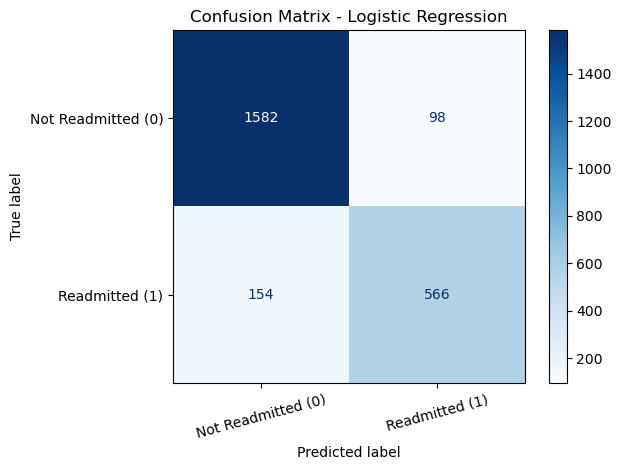


KNN
TN = 1587 | FP = 93
FN = 287 | TP = 433


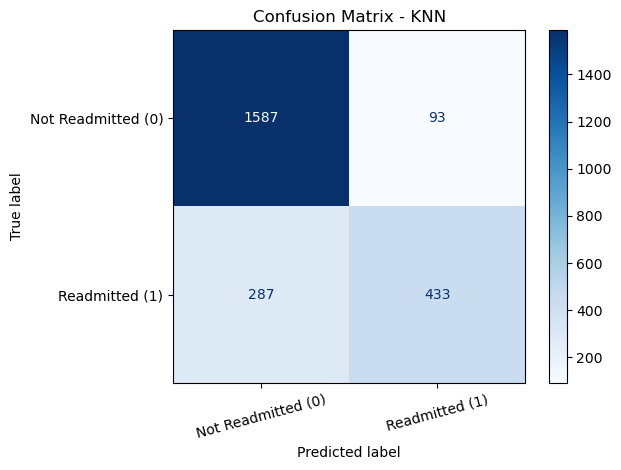


Decision Tree
TN = 1422 | FP = 258
FN = 238 | TP = 482


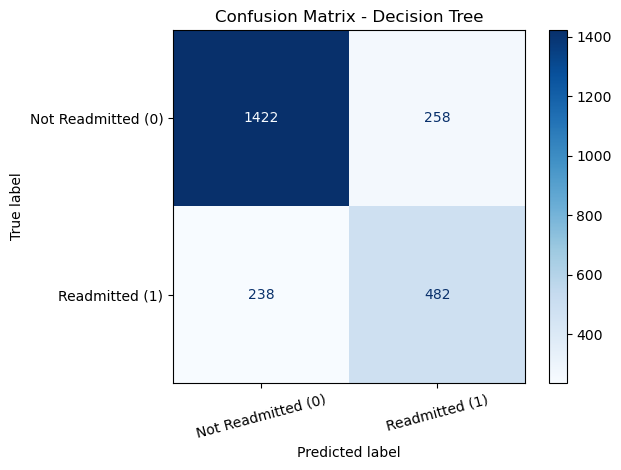

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred)

    print(f"\n{name}")
    print("TN =", cm[0, 0], "| FP =", cm[0, 1])
    print("FN =", cm[1, 0], "| TP =", cm[1, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Readmitted (0)", "Readmitted (1)"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

### ROC Curve Analysis

Objective

The ROC curve evaluates how well each model distinguishes between patients who are readmitted and those who are not readmitted at different classification thresholds.

Interpretation

- The ROC curve plots the True Positive Rate against the False Positive Rate.
- The AUC (Area Under the Curve) summarizes the model's ability to distinguish between the two classes.
- A higher ROC-AUC generally indicates better class discrimination.

Model Comparison

The ROC curves of Logistic Regression, KNN, and Decision Tree are displayed on the same graph for comparison. The AUC value should be shown in each model's legend.

Conclusion

ROC-AUC is considered alongside recall, precision, F1-score, and the confusion matrix rather than being used as the only measure of model performance.

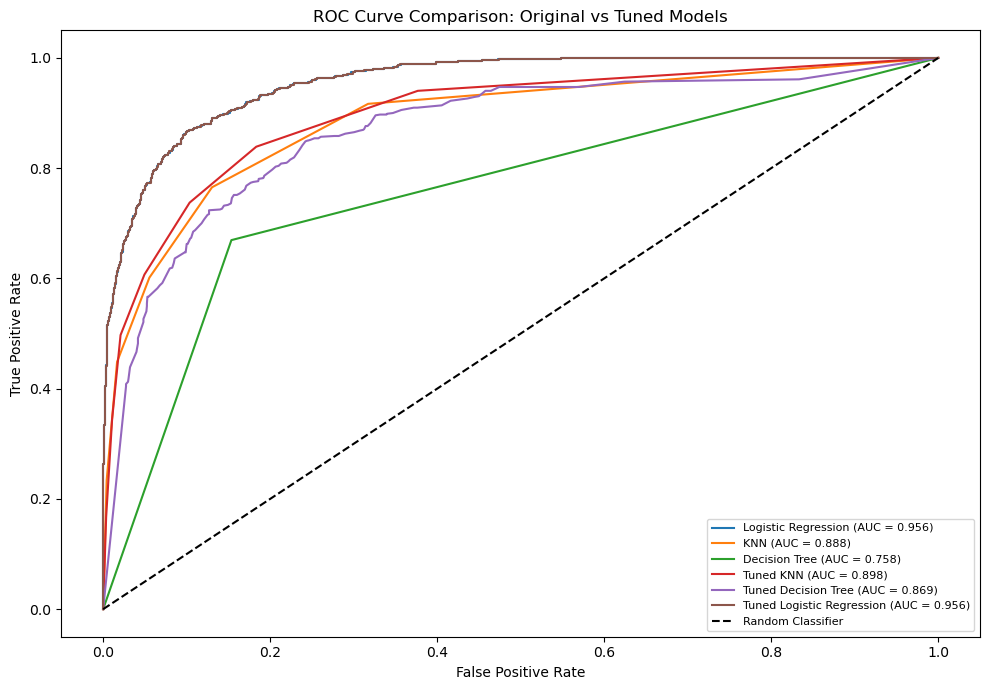

In [37]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

models_for_roc = {
    "Logistic Regression": pipelines["Logistic Regression"],
    "KNN": pipelines["KNN"],
    "Decision Tree": pipelines["Decision Tree"],
    "Tuned KNN": tuned_models["Tuned KNN"],
    "Tuned Decision Tree": tuned_models["Tuned Decision Tree"],
    "Tuned Logistic Regression": best_lr
}

plt.figure(figsize=(10, 7))

for name, model in models_for_roc.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_value = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.title("ROC Curve Comparison: Original vs Tuned Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

#11. Train-Test Performance and Fit Diagnosis

Objective

Training and testing performance are compared to assess how well each model generalizes to unseen data.

Results

- Logistic Regression: Train accuracy = 0.8946; test accuracy = 0.8950. The scores are very similar, indicating a small generalization gap.
- KNN: Train accuracy = 0.8924; test accuracy = 0.8417. The gap suggests some generalization difficulty.
- Decision Tree: Train accuracy = 1.0000; test accuracy = 0.7933. The large gap indicates overfitting.

Interpretation

Logistic Regression shows the most consistent train-test accuracy. The Decision Tree fits the training data perfectly but performs considerably worse on the test data, indicating overfitting. KNN also has a train-test performance gap, although smaller than the original Decision Tree.

Conclusion

Based on these accuracy results, Logistic Regression generalizes best among the three original models. The tuned models must also be considered before making the final recommendation.

In [28]:
fit_results = []

for name, pipeline in pipelines.items():
    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    fit_results.append({
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Accuracy Gap": train_acc - test_acc
    })

fit_df = pd.DataFrame(fit_results).set_index("Model")
display(fit_df.round(4))

,Train Accuracy,Test Accuracy,Accuracy Gap
Model,,,
Logistic Regression,0.8946,0.8950,-0.0004
KNN,0.8924,0.8417,0.0507
Decision Tree,1.0000,0.7933,0.2067


### Training vs. Test Accuracy Visualization

The graph compares training accuracy with test accuracy for each original model. A large difference can indicate overfitting, while similar values suggest more consistent performance. Consider this evidence alongside the full evaluation metrics.


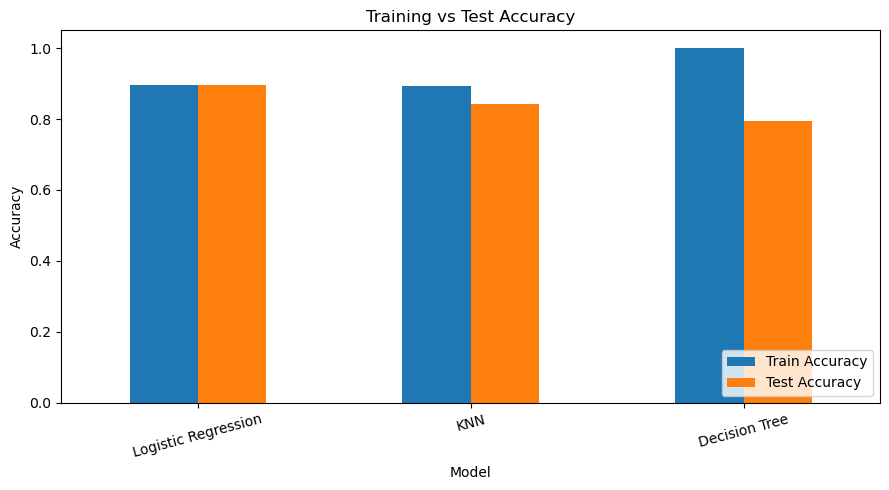

In [29]:
fit_df[["Train Accuracy", "Test Accuracy"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Training vs Test Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# 14. Original Model Performance Comparison

**Objective**

Compare Logistic Regression, KNN, and Decision Tree using their test-set metrics.

**Interpretation**

The chart compares accuracy, precision, recall, and F1-score for the three original models. Compare these results with the confusion matrices and ROC-AUC values before choosing a model.


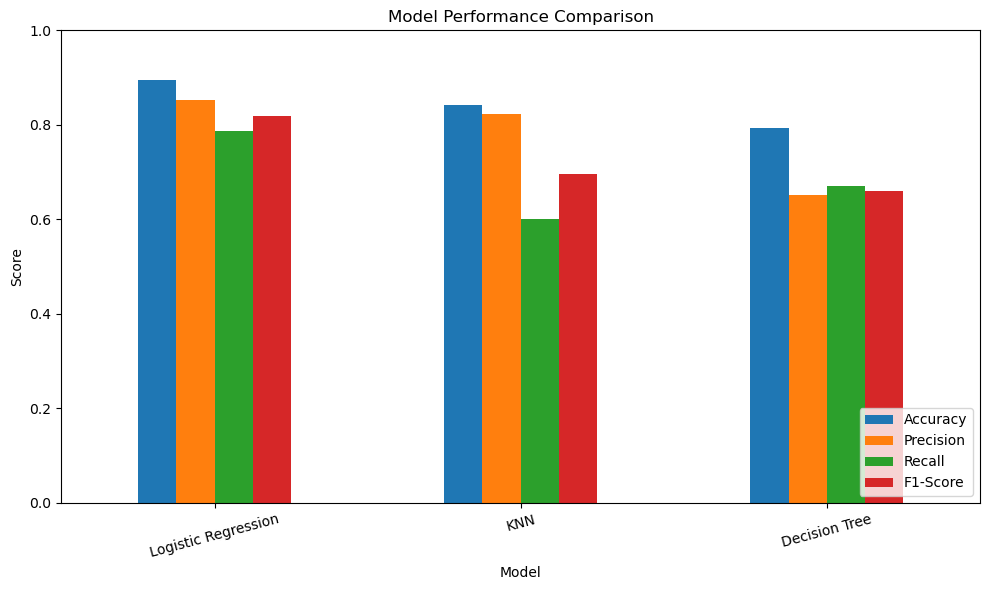

In [30]:
import matplotlib.pyplot as plt

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

results_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

#Model Hyperparameter Tuning

Objective

The objective is to improve model performance by testing different hyperparameter settings for KNN and Decision Tree.

Method

- GridSearchCV is used to test different parameter combinations.
- Five-fold cross-validation ("cv=5") is used to evaluate each combination.
- F1-score is used as the scoring metric.
- Tuning is performed using the training data only, keeping the test set for final evaluation.

Interpretation

The best parameter settings are selected based on the cross-validation F1-score. The tuned models are then evaluated on the test set and compared with the original models.

In [31]:
from sklearn.model_selection import GridSearchCV

# KNN experiments
knn_search = GridSearchCV(
    estimator=pipelines["KNN"],
    param_grid={
        "classifier__n_neighbors": [3, 5, 7, 9, 11],
        "classifier__weights": ["uniform", "distance"]
    },
    scoring="f1",
    cv=5,
    n_jobs=-1
)

knn_search.fit(X_train, y_train)

print("Best KNN settings:", knn_search.best_params_)
print("Best KNN CV F1-score:", round(knn_search.best_score_, 4))


# Decision Tree experiments
tree_search = GridSearchCV(
    estimator=pipelines["Decision Tree"],
    param_grid={
        "classifier__max_depth": [3, 5, 10, None],
        "classifier__min_samples_leaf": [1, 5, 10],
        "classifier__min_samples_split": [2, 10]
    },
    scoring="f1",
    cv=5,
    n_jobs=-1
)

tree_search.fit(X_train, y_train)

print("\nBest Decision Tree settings:", tree_search.best_params_)
print("Best Decision Tree CV F1-score:", round(tree_search.best_score_, 4))

Best KNN settings: {'classifier__n_neighbors': 7, 'classifier__weights': 'uniform'}
Best KNN CV F1-score: 0.7045

Best Decision Tree settings: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2}
Best Decision Tree CV F1-score: 0.7045


#Evaluation of Tuned Models

Objective

The objective is to evaluate the tuned KNN and Decision Tree models on the test dataset.

Method

The tuned models are evaluated using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

Interpretation

These metrics help compare the performance of the tuned models. The results are compared with the original models to determine whether hyperparameter tuning improved performance.

In [32]:
tuned_models = {
    "Tuned KNN": knn_search.best_estimator_,
    "Tuned Decision Tree": tree_search.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results).set_index("Model")
display(tuned_results_df.round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Tuned KNN,0.8475,0.8404,0.6069,0.7048,0.8981
Tuned Decision Tree,0.8292,0.7279,0.6875,0.7071,0.8692


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

lr_grid = GridSearchCV(
    lr_pipeline,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Best parameters:", lr_grid.best_params_)
print("Best cross-validation F1-score:", round(lr_grid.best_score_, 4))

Best parameters: {'model__C': 10}
Best cross-validation F1-score: 0.8142


In [34]:
best_lr = lr_grid.best_estimator_

y_pred_lr_tuned = best_lr.predict(X_test)
y_prob_lr_tuned = best_lr.predict_proba(X_test)[:, 1]

print("Tuned Logistic Regression Results")
print("Train Accuracy:", round(best_lr.score(X_train, y_train), 4))
print("Test Accuracy:", round(best_lr.score(X_test, y_test), 4))

print("Precision:", round(precision_score(y_test, y_pred_lr_tuned), 4))
print("Recall:", round(recall_score(y_test, y_pred_lr_tuned), 4))
print("F1-score:", round(f1_score(y_test, y_pred_lr_tuned), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr_tuned), 4))

Tuned Logistic Regression Results
Train Accuracy: 0.8945
Test Accuracy: 0.895
Precision: 0.8524
Recall: 0.7861
F1-score: 0.8179
ROC-AUC: 0.9562


### Tuned Logistic Regression — Conclusion

Logistic Regression was tested with different values of the regularization parameter `C` using 5-fold cross-validation and F1-score. The best parameter was `C = 10`, with a cross-validation F1-score of approximately `0.8142`.

The tuned model's test metrics are displayed in the evaluation cell above. In the recorded results, its test performance matched the original Logistic Regression model. Therefore, tuning did not meaningfully improve test-set performance, although it provided a cross-validation-based parameter selection.


### Final Model Comparison

Objective

The objective is to compare the original and tuned models using a common set of training and testing performance metrics.

Method

The results of Logistic Regression, KNN, Decision Tree, Tuned KNN, and Tuned Decision Tree are combined into one summary table. The table includes training accuracy, test accuracy, precision, recall, F1-score, ROC-AUC, and accuracy gap.

Interpretation

The summary table supports a consistent comparison of all five model configurations. The accuracy gap helps assess generalization, while precision, recall, F1-score, and ROC-AUC provide additional information about predictive performance.

Model Selection

The final model should be selected after considering the evaluation metrics, overfitting risk, and the healthcare importance of identifying patients who may be readmitted within 30 days.

In [35]:
# Combine original and tuned model results
final_comparison = pd.concat([
    results_df,
    tuned_results_df
])

# Add train accuracy for each model
train_accuracy = {}

for name, pipeline in pipelines.items():
    train_accuracy[name] = accuracy_score(
        y_train, pipeline.predict(X_train)
    )

for name, model in tuned_models.items():
    train_accuracy[name] = accuracy_score(
        y_train, model.predict(X_train)
    )

final_comparison.insert(
    0,
    "Train Accuracy",
    [train_accuracy[name] for name in final_comparison.index]
)

final_comparison["Accuracy Gap"] = (
    final_comparison["Train Accuracy"] -
    final_comparison["Accuracy"]
)

# Add tuned Logistic Regression results
final_comparison.loc["Tuned Logistic Regression"] = {
    "Train Accuracy": 0.8945,
    "Accuracy": 0.8950,
    "Precision": 0.8524,
    "Recall": 0.7861,
    "F1-Score": 0.8179,
    "ROC-AUC": 0.9562,
    "Accuracy Gap": -0.0005
}
display(final_comparison.round(4))

,Train Accuracy,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Accuracy Gap
Model,,,,,,,
Logistic Regression,0.8946,0.8950,0.8524,0.7861,0.8179,0.9562,-0.0004
KNN,0.8924,0.8417,0.8232,0.6014,0.6950,0.8878,0.0507
Decision Tree,1.0000,0.7933,0.6514,0.6694,0.6603,0.7579,0.2067
Tuned KNN,0.8833,0.8475,0.8404,0.6069,0.7048,0.8981,0.0358
Tuned Decision Tree,0.9014,0.8292,0.7279,0.6875,0.7071,0.8692,0.0722
Tuned Logistic Regression,0.8945,0.8950,0.8524,0.7861,0.8179,0.9562,-0.0005


### Original vs. Tuned Model Performance Visualization

This chart compares the original and tuned configurations on the same test-set metrics. It should be placed after the final comparison table has been created, including the tuned Logistic Regression results.


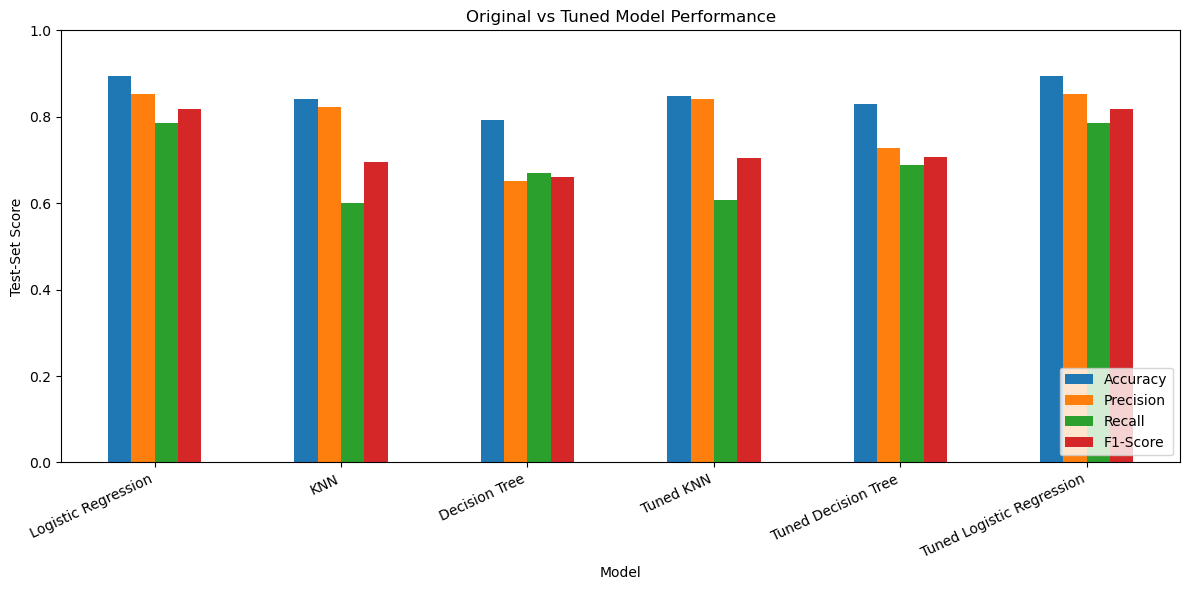

In [36]:
# Plot test-set metrics for all original and tuned model configurations
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score"]

final_comparison[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Original vs Tuned Model Performance")
plt.ylabel("Test-Set Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### Original vs Tuned Model Performance — Interpretation

This graph compares the original and tuned model configurations using test-set accuracy, precision, recall, and F1-score. Use it together with the final summary table, ROC curves, confusion matrices, and train-test accuracy gaps.

Hyperparameter tuning improved some metrics for KNN and Decision Tree, but the best model should be chosen using several metrics and the healthcare context rather than accuracy alone.


### Final Model Recommendation

Recommended Model

Based on the current evaluation results, Logistic Regression is the strongest candidate among the three original models, while the tuned models should also be considered before making the final selection.

Justification

- Logistic Regression achieved a test accuracy of 0.8950 and ROC-AUC of 0.9562.
- It achieved a recall of 0.7861 and an F1-score of 0.8179.
- Its training and testing accuracies are very similar, indicating good generalization on this split.
- The tuned Decision Tree achieved a higher F1-score than the original Decision Tree, so tuning improved its test performance.

Healthcare Consideration

Recall is important because failing to identify a patient who is later readmitted may mean missing an opportunity for additional follow-up. Precision and false positives must also be considered to avoid unnecessary follow-up.

Limitation

These results are based on this dataset and test split. Further validation is required before using any model to support real clinical decisions.